# Atelier ML - Partie 1 Préparation des données Pokémon

In [28]:
import numpy as nmp 
import pandas as pd 
pd.set_option('display.max_columns', None) # Afficher toutes les colonnes

## 1. Chargement du Pokédex

In [ ]:
nosPokemons = pd.read_csv("datas/pokedex.csv")
print(nosPokemons.columns.values)

<StringArray>
[                 'NUMERO',                     'NOM',
                  'TYPE_1',                  'TYPE_2',
           'POINTS_DE_VIE',          'NIVEAU_ATTAQUE',
          'NIVEAU_DEFENSE', 'NIVEAU_ATTAQUE_SPECIALE',
 'NIVEAU_DEFENSE_SPECIALE',                 'VITESSE',
      'NOMBRE_GENERATIONS',              'LEGENDAIRE']
Length: 12, dtype: str


: 

: 

: 

: 

In [ ]:
nosPokemons.head(10)

,NUMERO,NOM,TYPE_1,TYPE_2,POINTS_DE_VIE,NIVEAU_ATTAQUE,NIVEAU_DEFENSE,NIVEAU_ATTAQUE_SPECIALE,NIVEAU_DEFENSE_SPECIALE,VITESSE,NOMBRE_GENERATIONS,LEGENDAIRE
0,1,Bulbizarre,Herbe,Poison,45,49,49,65,65,45,1,FAUX
1,2,Herbizarre,Herbe,Poison,60,62,63,80,80,60,1,FAUX
2,3,Florizarre,Herbe,Poison,80,82,83,100,100,80,1,FAUX
3,4,Mega Florizarre,Herbe,Poison,80,100,123,122,120,80,1,FAUX
4,5,Salameche,Feu,NaN,39,52,43,60,50,65,1,FAUX
5,6,Reptincel,Feu,NaN,58,64,58,80,65,80,1,FAUX
6,7,Dracaufeu,Feu,Vol,78,84,78,109,85,100,1,FAUX
7,8,Mega Dracaufeu X,Feu,Dragon,78,130,111,130,85,100,1,FAUX
8,9,Mega Dracaufeu Y,Feu,Vol,78,104,78,159,115,100,1,FAUX
9,10,Carapuce,Eau,NaN,44,48,65,50,64,43,1,FAUX


: 

: 

: 

: 

## 2. Transformation de LEGENDAIRE (VRAI/FAUX -> 1/0)

In [ ]:
nosPokemonsClean = nosPokemons.copy()
nosPokemonsClean["LEGENDAIRE"] = nosPokemonsClean["LEGENDAIRE"].map({"VRAI": 1, "FAUX": 0}).astype(int)
nosPokemonsClean.head()


,NUMERO,NOM,TYPE_1,TYPE_2,POINTS_DE_VIE,NIVEAU_ATTAQUE,NIVEAU_DEFENSE,NIVEAU_ATTAQUE_SPECIALE,NIVEAU_DEFENSE_SPECIALE,VITESSE,NOMBRE_GENERATIONS,LEGENDAIRE
0,1,Bulbizarre,Herbe,Poison,45,49,49,65,65,45,1,0
1,2,Herbizarre,Herbe,Poison,60,62,63,80,80,60,1,0
2,3,Florizarre,Herbe,Poison,80,82,83,100,100,80,1,0
3,4,Mega Florizarre,Herbe,Poison,80,100,123,122,120,80,1,0
4,5,Salameche,Feu,NaN,39,52,43,60,50,65,1,0


: 

: 

: 

: 

## 3. Données manquantes

In [ ]:
print(nosPokemonsClean.shape)
nosPokemonsClean.info()

(800, 12)
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   NUMERO                   800 non-null    int64
 1   NOM                      799 non-null    str  
 2   TYPE_1                   800 non-null    str  
 3   TYPE_2                   413 non-null    str  
 4   POINTS_DE_VIE            800 non-null    int64
 5   NIVEAU_ATTAQUE           800 non-null    int64
 6   NIVEAU_DEFENSE           800 non-null    int64
 7   NIVEAU_ATTAQUE_SPECIALE  800 non-null    int64
 8   NIVEAU_DEFENSE_SPECIALE  800 non-null    int64
 9   VITESSE                  800 non-null    int64
 10  NOMBRE_GENERATIONS       800 non-null    int64
 11  LEGENDAIRE               800 non-null    int64
dtypes: int64(9), str(3)
memory usage: 75.1 KB


: 

: 

: 

: 

In [ ]:
nosPokemonsClean[nosPokemonsClean['NOM'].isnull()]

,NUMERO,NOM,TYPE_1,TYPE_2,POINTS_DE_VIE,NIVEAU_ATTAQUE,NIVEAU_DEFENSE,NIVEAU_ATTAQUE_SPECIALE,NIVEAU_DEFENSE_SPECIALE,VITESSE,NOMBRE_GENERATIONS,LEGENDAIRE
62,63,NaN,Combat,NaN,65,105,60,60,70,95,1,0


: 

: 

: 

: 

In [ ]:
print(nosPokemonsClean['NOM'][61])
print(nosPokemonsClean['NOM'][63])

Ferosinge
Caninos


: 

: 

: 

: 

In [ ]:
nosPokemonsClean.loc[62, 'NOM'] = "Colossinge"
print(nosPokemonsClean['NOM'][62])

Colossinge


: 

: 

: 

: 

## 4. Observations des combats

In [ ]:
combats = pd.read_csv("datas/combats.csv")
print(combats.columns.values)
print(combats.shape)
combats.info()
combats.head(10)

<StringArray>
['Premier_Pokemon', 'Second_Pokemon', 'Pokemon_Gagnant']
Length: 3, dtype: str
(50000, 3)
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Premier_Pokemon  50000 non-null  int64
 1   Second_Pokemon   50000 non-null  int64
 2   Pokemon_Gagnant  50000 non-null  int64
dtypes: int64(3)
memory usage: 1.1 MB


,Premier_Pokemon,Second_Pokemon,Pokemon_Gagnant
0,266,298,298
1,702,701,701
2,191,668,668
3,237,683,683
4,151,231,151
5,657,752,657
6,192,134,134
7,73,545,545
8,220,763,763
9,302,31,31


: 

: 

: 

: 

## 5. Nombre de combats menés

In [ ]:
nbFoisPremierPosition = combats.groupby('Premier_Pokemon').count()
nbFoisSecondePosition = combats.groupby('Second_Pokemon').count()

nombreTotalDeCombats = nbFoisPremierPosition.Pokemon_Gagnant + nbFoisSecondePosition.Pokemon_Gagnant
nombreTotalDeCombats

Premier_Pokemon
1      133
2      121
3      132
4      125
5      112
      ... 
796    105
797    131
798    119
799    144
800    121
Name: Pokemon_Gagnant, Length: 784, dtype: int64

: 

: 

: 

: 

## 6. Nombre de combats gagnés

In [ ]:
nombreDeVictoires = combats.groupby('Pokemon_Gagnant').count()
print(len(nombreDeVictoires), "Pokémons ont gagné au moins un combat")
print("Pokémon 228 :", nombreDeVictoires.Premier_Pokemon[228], "victoires sur", nombreTotalDeCombats[228], "combats")

783 Pokémons ont gagné au moins un combat
Pokémon 228 : 104 victoires sur 150 combats


: 

: 

: 

: 

In [ ]:
# Pokémons qui ont combattu mais jamais gagné
jamaisGagne = nombreTotalDeCombats.index.difference(nombreDeVictoires.index)
nosPokemonsClean[nosPokemonsClean.NUMERO.isin(jamaisGagne)]

,NUMERO,NOM,TYPE_1,TYPE_2,POINTS_DE_VIE,NIVEAU_ATTAQUE,NIVEAU_DEFENSE,NIVEAU_ATTAQUE_SPECIALE,NIVEAU_DEFENSE_SPECIALE,VITESSE,NOMBRE_GENERATIONS,LEGENDAIRE
230,231,Caratroc,Insecte,Roche,20,10,230,10,230,5,2,0


: 

: 

: 

: 

In [ ]:
# Pokémons du Pokédex qui n'ont jamais combattu
jamaisCombattu = set(nosPokemonsClean.NUMERO) - set(nombreTotalDeCombats.index)
nosPokemonsClean[nosPokemonsClean.NUMERO.isin(jamaisCombattu)][['NUMERO', 'NOM']]

,NUMERO,NOM
11,12,Tortank
32,33,Sabelette
45,46,Grodoudou
65,66,Ptitard
77,78,Empiflor
89,90,Magneton
143,144,Metamorph
182,183,Migalos
235,236,Ursaring
321,322,Hariyama


: 

: 

: 

: 

## 7. Agregation avec le Pokedex

In [ ]:
listeAAgreger = combats.groupby('Pokemon_Gagnant').count()
listeAAgreger = listeAAgreger.sort_index()

listeAAgreger['NBR_COMBATS'] = nbFoisPremierPosition.Pokemon_Gagnant + nbFoisSecondePosition.Pokemon_Gagnant
listeAAgreger['NBR_VICTOIRES'] = nombreDeVictoires.Premier_Pokemon
listeAAgreger['POURCENTAGE_DE_VICTOIRES'] = listeAAgreger['NBR_VICTOIRES'] / listeAAgreger['NBR_COMBATS']
listeAAgreger.head()

,Premier_Pokemon,Second_Pokemon,NBR_COMBATS,NBR_VICTOIRES,POURCENTAGE_DE_VICTOIRES
Pokemon_Gagnant,,,,,
1,37,37,133,37,0.278195
2,46,46,121,46,0.380165
3,89,89,132,89,0.674242
4,70,70,125,70,0.560000
5,55,55,112,55,0.491071


: 

: 

: 

: 

In [ ]:
nouveauPokedex = nosPokemonsClean.merge(listeAAgreger, left_on='NUMERO', right_index=True, how='left')
nouveauPokedex.describe()

,NUMERO,POINTS_DE_VIE,NIVEAU_ATTAQUE,NIVEAU_DEFENSE,NIVEAU_ATTAQUE_SPECIALE,NIVEAU_DEFENSE_SPECIALE,VITESSE,NOMBRE_GENERATIONS,LEGENDAIRE,Premier_Pokemon,Second_Pokemon,NBR_COMBATS,NBR_VICTOIRES,POURCENTAGE_DE_VICTOIRES
count,800.0000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.00000,800.00000,783.000000,783.000000,783.000000,783.000000,783.000000
mean,400.5000,69.258750,79.001250,73.842500,72.820000,71.902500,68.277500,3.32375,0.08125,63.856960,63.856960,127.541507,63.856960,0.501538
std,231.0844,25.534669,32.457366,31.183501,32.722294,27.828916,29.060474,1.66129,0.27339,32.925941,32.925941,11.397402,32.925941,0.254993
min,1.0000,1.000000,5.000000,5.000000,10.000000,20.000000,5.000000,1.00000,0.00000,3.000000,3.000000,92.000000,3.000000,0.021739
25%,200.7500,50.000000,55.000000,50.000000,49.750000,50.000000,45.000000,2.00000,0.00000,36.000000,36.000000,120.000000,36.000000,0.284228
50%,400.5000,65.000000,75.000000,70.000000,65.000000,70.000000,65.000000,3.00000,0.00000,62.000000,62.000000,128.000000,62.000000,0.491071
75%,600.2500,80.000000,100.000000,90.000000,95.000000,90.000000,90.000000,5.00000,0.00000,91.000000,91.000000,135.000000,91.000000,0.717644
max,800.0000,255.000000,190.000000,230.000000,194.000000,230.000000,180.000000,6.00000,1.00000,152.000000,152.000000,164.000000,152.000000,0.984496


: 

: 

: 

: 

In [ ]:
nouveauPokedex.sort_values('POURCENTAGE_DE_VICTOIRES', ascending=False).head(10)[['NUMERO','NOM','TYPE_1','NBR_COMBATS','NBR_VICTOIRES','POURCENTAGE_DE_VICTOIRES']]

,NUMERO,NOM,TYPE_1,NBR_COMBATS,NBR_VICTOIRES,POURCENTAGE_DE_VICTOIRES
154,155,Mega Ptera,Roche,129.0,127.0,0.984496
512,513,Dimoret,Obscur,119.0,116.0,0.974790
703,704,Boreas forme Therian,Vol,125.0,121.0,0.968000
19,20,Mega Dardagnan,Insecte,119.0,115.0,0.966387
153,154,Ptera,Roche,141.0,136.0,0.964539
476,477,Mega Lockpin,Normal,129.0,124.0,0.961240
726,727,Amphinobi,Eau,127.0,122.0,0.960630
716,717,Meloetta forme Pirouette,Normal,123.0,118.0,0.959350
164,165,Mega Mewtwo Y,Psy,125.0,119.0,0.952000
349,350,Mega Sharpedo,Eau,120.0,114.0,0.950000


: 

: 

: 

: 

# Partie 2 – Analyse des données
## 8. Statistiques descriptives

In [30]:
nouveauPokedex.describe()

,NUMERO,POINTS_DE_VIE,NIVEAU_ATTAQUE,NIVEAU_DEFENSE,NIVEAU_ATTAQUE_SPECIALE,NIVEAU_DEFENSE_SPECIALE,VITESSE,NOMBRE_GENERATIONS,LEGENDAIRE,Premier_Pokemon,Second_Pokemon,NBR_COMBATS,NBR_VICTOIRES,POURCENTAGE_DE_VICTOIRES
count,800.0000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.00000,800.00000,783.000000,783.000000,783.000000,783.000000,783.000000
mean,400.5000,69.258750,79.001250,73.842500,72.820000,71.902500,68.277500,3.32375,0.08125,63.856960,63.856960,127.541507,63.856960,0.501538
std,231.0844,25.534669,32.457366,31.183501,32.722294,27.828916,29.060474,1.66129,0.27339,32.925941,32.925941,11.397402,32.925941,0.254993
min,1.0000,1.000000,5.000000,5.000000,10.000000,20.000000,5.000000,1.00000,0.00000,3.000000,3.000000,92.000000,3.000000,0.021739
25%,200.7500,50.000000,55.000000,50.000000,49.750000,50.000000,45.000000,2.00000,0.00000,36.000000,36.000000,120.000000,36.000000,0.284228
50%,400.5000,65.000000,75.000000,70.000000,65.000000,70.000000,65.000000,3.00000,0.00000,62.000000,62.000000,128.000000,62.000000,0.491071
75%,600.2500,80.000000,100.000000,90.000000,95.000000,90.000000,90.000000,5.00000,0.00000,91.000000,91.000000,135.000000,91.000000,0.717644
max,800.0000,255.000000,190.000000,230.000000,194.000000,230.000000,180.000000,6.00000,1.00000,152.000000,152.000000,164.000000,152.000000,0.984496


## 9. Types de Pokémons à posséder

Matplotlib is building the font cache; this may take a moment.


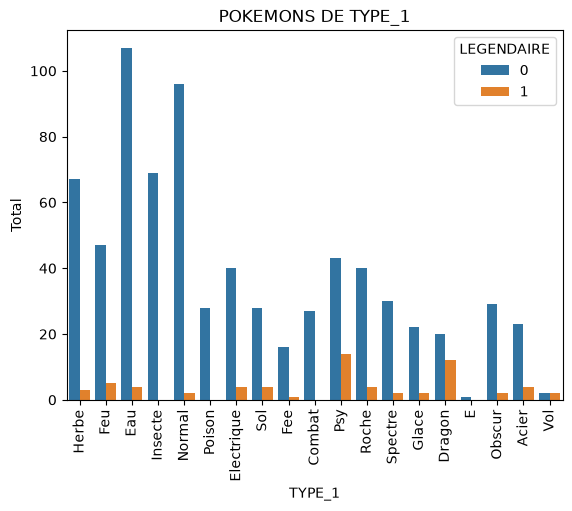

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x="TYPE_1", hue="LEGENDAIRE", data=nouveauPokedex)
plt.xticks(rotation=90)
plt.xlabel('TYPE_1')
plt.ylabel('Total')
plt.title("POKEMONS DE TYPE_1")
plt.show()

## 10. Types gagnants et perdants

In [31]:
nouveauPokedex.groupby('TYPE_1').agg({"POURCENTAGE_DE_VICTOIRES": "mean"}).sort_values(by="POURCENTAGE_DE_VICTOIRES")

,POURCENTAGE_DE_VICTOIRES
TYPE_1,
Fee,0.329300
E,0.343750
Roche,0.404852
Acier,0.424529
Poison,0.433262
Insecte,0.439006
Glace,0.439604
Herbe,0.440364
Eau,0.470520


## 11. Corrélations

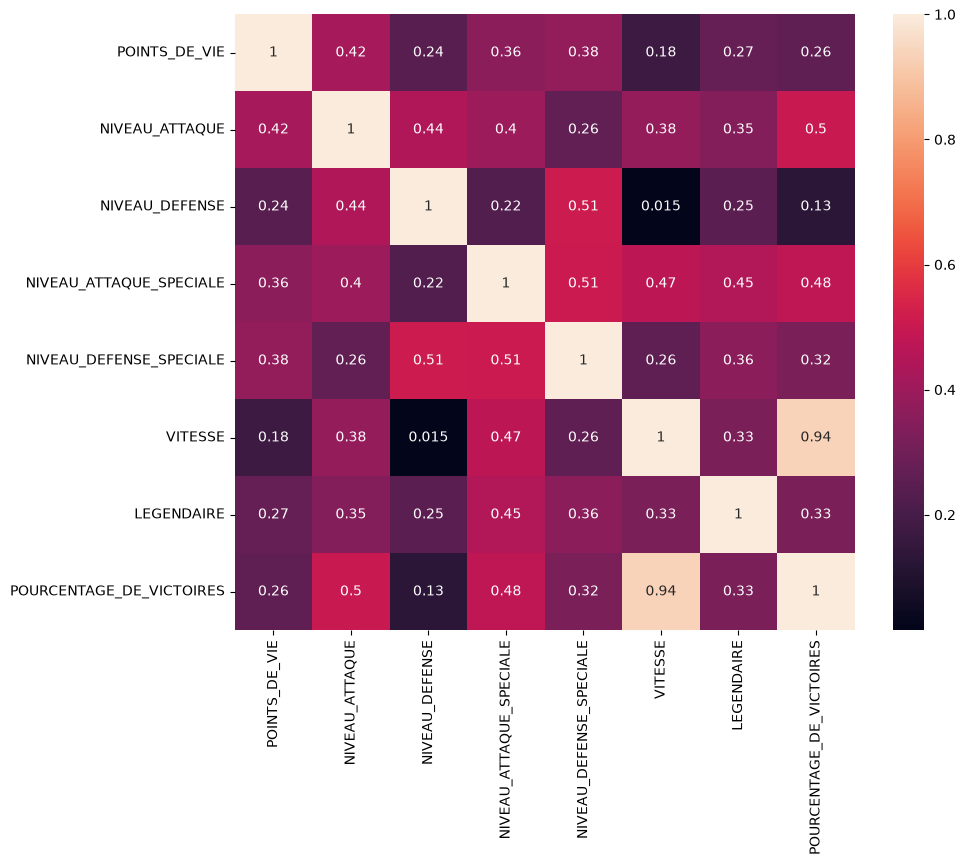

In [32]:
corr = nouveauPokedex.loc[:, ['POINTS_DE_VIE', 'NIVEAU_ATTAQUE', 'NIVEAU_DEFENSE',
                              'NIVEAU_ATTAQUE_SPECIALE', 'NIVEAU_DEFENSE_SPECIALE',
                              'VITESSE', 'LEGENDAIRE', 'POURCENTAGE_DE_VICTOIRES']].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, xticklabels=corr.columns, yticklabels=corr.columns, annot=True)
plt.show()